In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

Load the dataset

In [14]:
ds = pd.read_csv("Dataset.csv")
print(ds.head())
print(ds.shape)

  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dr

Feature selection

In [15]:
features = ["type","country","release_year","listed_in","rating"]
x = ds[features]
print(x.head())

      type        country  release_year  \
0    Movie  United States          2020   
1  TV Show         France          2021   
2  TV Show  United States          2021   
3    Movie         Brazil          2021   
4    Movie  United States          1993   

                                           listed_in rating  
0                                      Documentaries  PG-13  
1  Crime TV Shows, International TV Shows, TV Act...  TV-MA  
2                 TV Dramas, TV Horror, TV Mysteries  TV-MA  
3                 Children & Family Movies, Comedies  TV-PG  
4   Dramas, Independent Movies, International Movies  TV-MA  


Preparing numerical and categorical feature

In [16]:
categorical_features = [
    "type",
    "country",
    "listed_in",
    "rating"
]
numerical_features = [
    "release_year"
]
preprocessor = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)
x_processed = preprocessor.fit_transform(x)
print("Feature preparation completed!")
print(x_processed.shape)

Feature preparation completed!
(8790, 616)


Find best no. of cluster by using Silhouette score technique

In [17]:
scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(x_processed)

    score = silhouette_score(
        x_processed,
        labels,
        sample_size=2000,
        random_state=42
    )

    scores.append(score)

    print("Clusters:", k,
          "Silhouette Score:", round(score, 3))


best_k = range(2, 7)[scores.index(max(scores))]

print("Best number of clusters:", best_k)

Clusters: 2 Silhouette Score: 0.335
Clusters: 3 Silhouette Score: 0.156
Clusters: 4 Silhouette Score: 0.114
Clusters: 5 Silhouette Score: 0.127
Clusters: 6 Silhouette Score: 0.125
Best number of clusters: 2


Apply k_mean model

In [18]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

ds['Cluster'] = kmeans.fit_predict(x_processed)

print(ds[['title', 'type', 'Cluster']].head(10))

                              title     type  Cluster
0              Dick Johnson Is Dead    Movie        1
1                         Ganglands  TV Show        1
2                     Midnight Mass  TV Show        1
3  Confessions of an Invisible Girl    Movie        1
4                           Sankofa    Movie        0
5     The Great British Baking Show  TV Show        1
6                      The Starling    Movie        1
7   Motu Patlu in the Game of Zones    Movie        1
8                      Je Suis Karl    Movie        1
9          Motu Patlu in Wonderland    Movie        1


Visualization of cluster

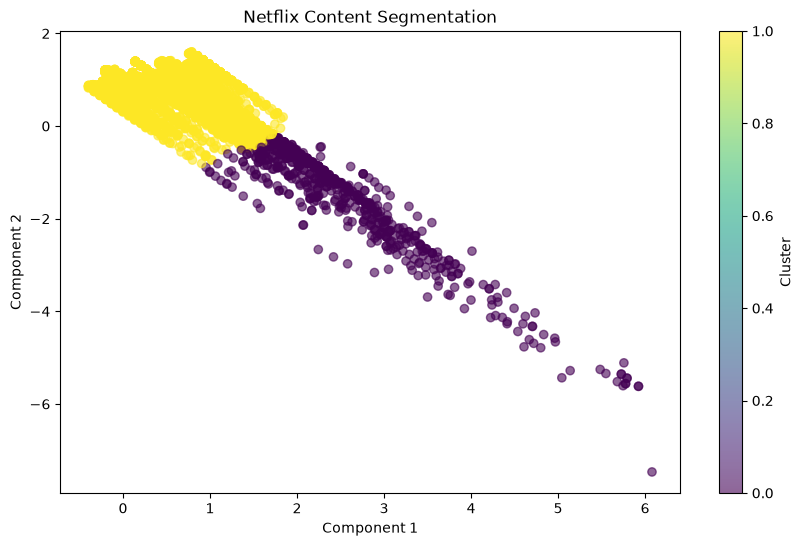

In [19]:
svd = TruncatedSVD(n_components=2, random_state=42)

X_2D = svd.fit_transform(x_processed)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=ds['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("Netflix Content Segmentation")

plt.colorbar(label="Cluster")
plt.show()

Identify cluster characteristics

In [20]:
cluster_summary = ds.groupby('Cluster').agg(
    Total_Titles=('title', 'count'),
    Average_Release_Year=('release_year', 'mean')
)

print(cluster_summary.round(2))

         Total_Titles  Average_Release_Year
Cluster                                    
0                 716               1990.25
1                8074               2016.31


popular feature of the cluster

In [21]:
for cluster in sorted(ds['Cluster'].unique()):

    cluster_data = ds[ds['Cluster'] == cluster]

    print("\nCluster:", cluster)

    print("Content Type:")
    print(cluster_data['type'].value_counts().head(3))

    print("Popular Genres:")
    print(cluster_data['listed_in'].value_counts().head(3))

    print("Popular Countries:")
    print(cluster_data['country'].value_counts().head(3))

    print("Ratings:")
    print(cluster_data['rating'].value_counts().head(3))


Cluster: 0
Content Type:
type
Movie      656
TV Show     60
Name: count, dtype: int64
Popular Genres:
listed_in
Action & Adventure                    27
Children & Family Movies, Comedies    26
Dramas                                25
Name: count, dtype: int64
Popular Countries:
country
United States     398
India             118
United Kingdom     44
Name: count, dtype: int64
Ratings:
rating
TV-14    166
R        165
PG-13    117
Name: count, dtype: int64

Cluster: 1
Content Type:
type
Movie      5470
TV Show    2604
Name: count, dtype: int64
Popular Genres:
listed_in
Documentaries                   352
Dramas, International Movies    342
Stand-Up Comedy                 317
Name: count, dtype: int64
Popular Countries:
country
United States     2842
India              939
United Kingdom     594
Name: count, dtype: int64
Ratings:
rating
TV-MA    3133
TV-14    1991
TV-PG     798
Name: count, dtype: int64
